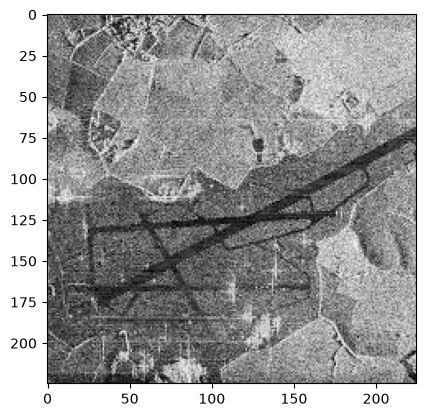

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math
import copy

image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 
plt.imshow(image_gray, cmap="gray")

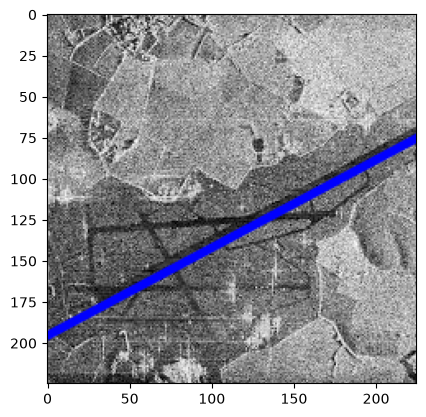

In [3]:
# №1
image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)  

canny = cv2.Canny(image_gray,50,150,apertureSize = 3)
lines = cv2.HoughLines(canny, 1, np.pi / 180, 140)
max_length = 0
longest_line = None

if lines is not None:
        for i in range(0, len(lines)):
            rho = lines[i][0][0]
            theta = lines[i][0][1]
            
            a = math.cos(theta)
            b = math.sin(theta)
            
            x0 = a * rho
            y0 = b * rho
            
            pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
            pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
            length = np.sqrt((pt1[0] - pt2[0]) ** 2 + (pt1[1] - pt2[1]) ** 2)
            
            if length > max_length:
                max_length = length
                longest_line = (pt1, pt2)
                
        if longest_line is not None:
            image_with_line = image.copy();
            cv2.line(image_with_line, longest_line[0], longest_line[1], (0, 0, 255), 3, cv2.LINE_AA)

plt.imshow(image_with_line, cmap="gray")

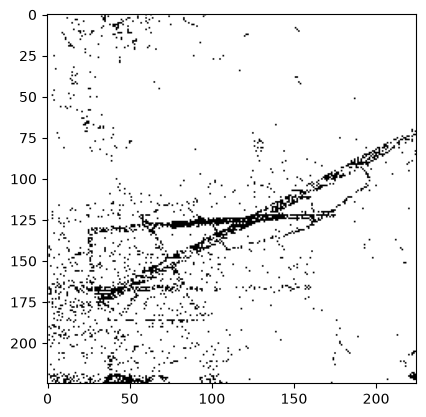

In [4]:
# №2

# Точечная бинаризация
bin_img = copy.deepcopy(image_gray)
T  = 50
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255

plt.imshow(bin_img, cmap="gray")

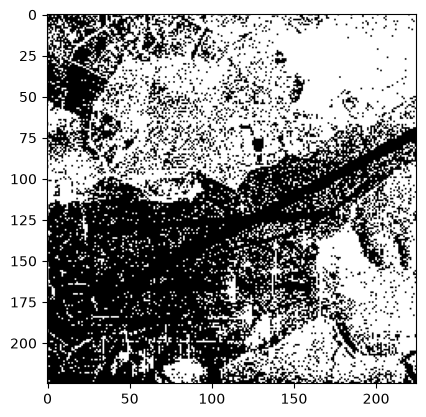

In [5]:
# бинаризация Отсу
_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(th2, cmap="gray")

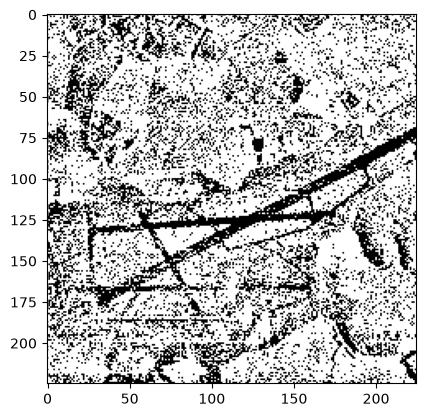

In [6]:
# адаптивная бинаризация
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,71,21)
plt.imshow(th3, cmap="gray")

In [7]:
# оператор Собеля
scale = 1
delta = 0
ddepth = cv2.CV_16S
grad_x = cv2.Sobel(image_gray, ddepth, 1, 0, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)
grad_y = cv2.Sobel(image_gray, ddepth, 0, 1, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)

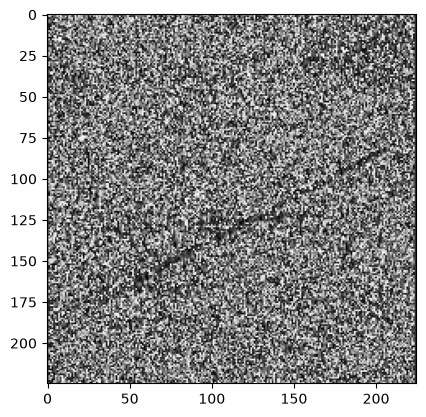

In [8]:
plt.imshow((grad_x - grad_x.min())*255, cmap="gray")

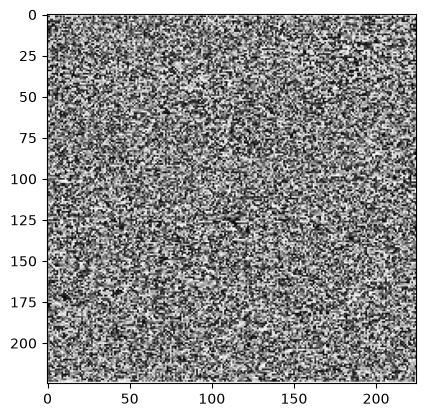

In [9]:
plt.imshow((grad_y - grad_y.min())*255, cmap="gray")

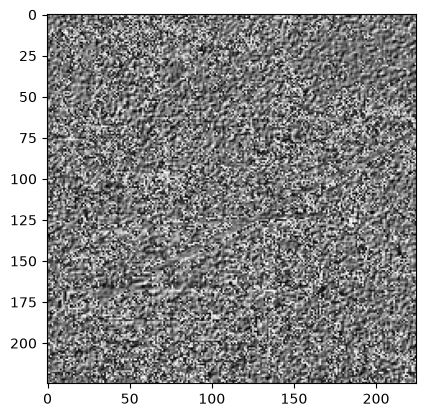

In [10]:
grad = cv2.addWeighted(grad_x, 0.5, grad_y, 0.5,0.0)
plt.imshow((grad - grad.min())*255, cmap="gray")

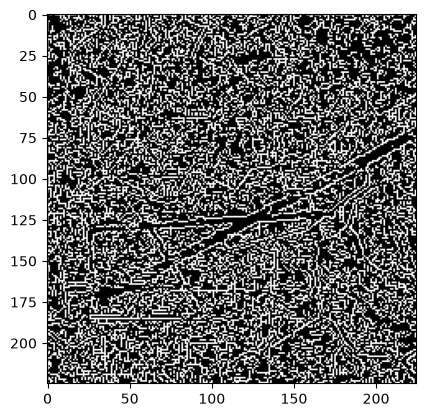

In [11]:
# Canny
edges = cv2.Canny(image_gray,100,200)
plt.imshow(edges, cmap="gray")

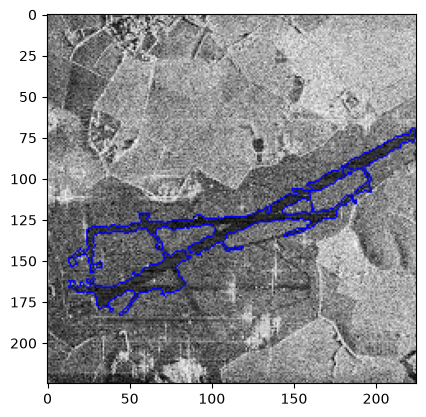

In [12]:
blur = cv2.GaussianBlur(bin_img, (5, 5), 0)
thresh = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 55, 2)
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
line_image = image.copy()
if contours:
    for contour in contours:
        area = cv2.contourArea(contour)
        if area > 500:
            cv2.drawContours(line_image, [contour], -1, (0, 0, 255), 1)
plt.imshow(line_image, cmap="gray")